<a href="https://colab.research.google.com/github/ZainabShehu1/AI-Housing-Support-Assistant/blob/main/AI_Housing_Support_Assistant.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

import pandas as pd

# Fictional enquiries — no real personal information
enquiries = [
    "There is mould growing on my bedroom wall",
    "My heating has stopped working",
    "I want to know how to apply for housing",
    "My landlord has not repaired a leaking roof",
    "I need information about rent support",
    "There is exposed electrical wiring in my kitchen",
    "How do I update my housing application?",
    "My front door lock is broken"
]

def classify_enquiry(message):
    text = message.lower()

    if any(word in text for word in
           ["electrical", "wiring", "lock"]):
        return "Potential safety concern"
    elif any(word in text for word in
             ["mould", "heating", "leaking", "repair"]):
        return "Repairs and maintenance"
    elif any(word in text for word in
             ["rent", "support"]):
        return "Financial support"
    else:
        return "General housing enquiry"

df = pd.DataFrame({"enquiry": enquiries})
df["category"] = df["enquiry"].apply(classify_enquiry)

print(df.to_string(index=False))


                                         enquiry                 category
       There is mould growing on my bedroom wall  Repairs and maintenance
                  My heating has stopped working  Repairs and maintenance
         I want to know how to apply for housing  General housing enquiry
     My landlord has not repaired a leaking roof  Repairs and maintenance
           I need information about rent support        Financial support
There is exposed electrical wiring in my kitchen Potential safety concern
         How do I update my housing application?  General housing enquiry
                    My front door lock is broken Potential safety concern


Number of enquiries: 8
category
Repairs and maintenance     3
General housing enquiry     2
Potential safety concern    2
Financial support           1
Name: count, dtype: int64


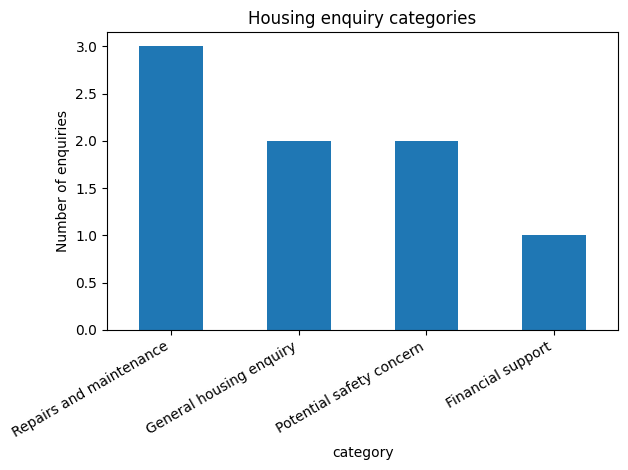

In [3]:
import matplotlib.pyplot as plt

print("Number of enquiries:", len(df))

print(df["category"].value_counts())

df["category"].value_counts().plot(

    kind="bar",

    title="Housing enquiry categories",

    ylabel="Number of enquiries"

)

plt.xticks(rotation=30, ha="right")

plt.tight_layout()

plt.show()

In [5]:

test_cases = [
    ("Exposed electrical wiring", "Potential safety concern"),
    ("My heating has stopped", "Repairs and maintenance"),
    ("I need rent support", "Financial support"),
    ("How do I apply for housing?", "General housing enquiry"),
    ("My front door lock is broken", "Potential safety concern"),
    ("There is mould in my bathroom", "Repairs and maintenance")
]

correct = 0

for message, expected in test_cases:
    prediction = classify_enquiry(message)
    passed = prediction == expected

    if passed:
        correct += 1

    print(f"Enquiry: {message}")
    print(f"Expected: {expected}")
    print(f"Predicted: {prediction}")
    print(f"Result: {'PASS' if passed else 'FAIL'}")
    print("-" * 40)

print(f"Tests passed: {correct}/{len(test_cases)}")


Enquiry: Exposed electrical wiring
Expected: Potential safety concern
Predicted: Potential safety concern
Result: PASS
----------------------------------------
Enquiry: My heating has stopped
Expected: Repairs and maintenance
Predicted: Repairs and maintenance
Result: PASS
----------------------------------------
Enquiry: I need rent support
Expected: Financial support
Predicted: Financial support
Result: PASS
----------------------------------------
Enquiry: How do I apply for housing?
Expected: General housing enquiry
Predicted: General housing enquiry
Result: PASS
----------------------------------------
Enquiry: My front door lock is broken
Expected: Potential safety concern
Predicted: Potential safety concern
Result: PASS
----------------------------------------
Enquiry: There is mould in my bathroom
Expected: Repairs and maintenance
Predicted: Repairs and maintenance
Result: PASS
----------------------------------------
Tests passed: 6/6


In [6]:

challenging_cases = [
    ("My heating is working perfectly", "General housing enquiry"),
    ("I have no electricity in my flat", "Potential safety concern"),
    ("I need help paying my rent", "Financial support"),
    ("There is water flooding my bedroom", "Potential safety concern"),
    ("I want to update my housing application", "General housing enquiry")
]

correct = 0

for message, expected in challenging_cases:
    predicted = classify_enquiry(message)
    passed = predicted == expected

    if passed:
        correct += 1

    print(f"Enquiry: {message}")
    print(f"Expected: {expected}")
    print(f"Predicted: {predicted}")
    print(f"Result: {'PASS' if passed else 'FAIL'}")
    print("-" * 40)

print(f"Challenging tests passed: {correct}/{len(challenging_cases)}")


Enquiry: My heating is working perfectly
Expected: General housing enquiry
Predicted: Repairs and maintenance
Result: FAIL
----------------------------------------
Enquiry: I have no electricity in my flat
Expected: Potential safety concern
Predicted: General housing enquiry
Result: FAIL
----------------------------------------
Enquiry: I need help paying my rent
Expected: Financial support
Predicted: Financial support
Result: PASS
----------------------------------------
Enquiry: There is water flooding my bedroom
Expected: Potential safety concern
Predicted: General housing enquiry
Result: FAIL
----------------------------------------
Enquiry: I want to update my housing application
Expected: General housing enquiry
Predicted: General housing enquiry
Result: PASS
----------------------------------------
Challenging tests passed: 2/5


In [9]:

def classify_enquiry_v2(message):
    text = message.lower()

    # Check for statements that indicate no problem
    if any(phrase in text for phrase in [
        "working perfectly",
        "working fine",
        "no problems"
    ]):
        return "General housing enquiry"

    # Check for potential safety concerns
    if any(phrase in text for phrase in [
        "electrical", "wiring", "broken lock",
        "lock is broken", "no electricity",
        "flooding", "flooded"
    ]):
        return "Potential safety concern"

    # Check for repair and maintenance problems
    if any(word in text for word in [
        "mould", "heating", "leaking",
        "repair", "broken"
    ]):
        return "Repairs and maintenance"

    # Check for financial support enquiries
    if any(word in text for word in [
        "rent", "financial support", "benefits"
    ]):
        return "Financial support"

    return "General housing enquiry"


# Compare both versions using the challenging tests
old_correct = 0
new_correct = 0

for message, expected in challenging_cases:
    old_prediction = classify_enquiry(message)
    new_prediction = classify_enquiry_v2(message)

    old_correct += old_prediction == expected
    new_correct += new_prediction == expected

    print(f"Enquiry: {message}")
    print(f"Original: {old_prediction}")
    print(f"Improved: {new_prediction}")
    print(f"Expected: {expected}")
    print("-" * 40)

print(f"Original classifier: {old_correct}/5")
print(f"Improved classifier: {new_correct}/5")


Enquiry: My heating is working perfectly
Original: Repairs and maintenance
Improved: General housing enquiry
Expected: General housing enquiry
----------------------------------------
Enquiry: I have no electricity in my flat
Original: General housing enquiry
Improved: Potential safety concern
Expected: Potential safety concern
----------------------------------------
Enquiry: I need help paying my rent
Original: Financial support
Improved: Financial support
Expected: Financial support
----------------------------------------
Enquiry: There is water flooding my bedroom
Original: General housing enquiry
Improved: Potential safety concern
Expected: Potential safety concern
----------------------------------------
Enquiry: I want to update my housing application
Original: General housing enquiry
Improved: General housing enquiry
Expected: General housing enquiry
----------------------------------------
Original classifier: 2/5
Improved classifier: 5/5


In [10]:

unseen_cases = [
    ("My boiler has broken down", "Repairs and maintenance"),
    ("Water is pouring through my ceiling", "Potential safety concern"),
    ("How can I apply for rent assistance?", "Financial support"),
    ("My heating works perfectly", "General housing enquiry"),
    ("There are sparks coming from a socket", "Potential safety concern"),
    ("I need to change my contact details", "General housing enquiry")
]

correct = 0

for message, expected in unseen_cases:
    prediction = classify_enquiry_v2(message)
    passed = prediction == expected
    correct += passed

    print(f"Enquiry: {message}")
    print(f"Expected: {expected}")
    print(f"Predicted: {prediction}")
    print(f"Result: {'PASS' if passed else 'FAIL'}")
    print("-" * 40)

print(f"Unseen tests passed: {correct}/{len(unseen_cases)}")


Enquiry: My boiler has broken down
Expected: Repairs and maintenance
Predicted: Repairs and maintenance
Result: PASS
----------------------------------------
Enquiry: Water is pouring through my ceiling
Expected: Potential safety concern
Predicted: General housing enquiry
Result: FAIL
----------------------------------------
Enquiry: How can I apply for rent assistance?
Expected: Financial support
Predicted: Financial support
Result: PASS
----------------------------------------
Enquiry: My heating works perfectly
Expected: General housing enquiry
Predicted: Repairs and maintenance
Result: FAIL
----------------------------------------
Enquiry: There are sparks coming from a socket
Expected: Potential safety concern
Predicted: General housing enquiry
Result: FAIL
----------------------------------------
Enquiry: I need to change my contact details
Expected: General housing enquiry
Predicted: General housing enquiry
Result: PASS
----------------------------------------
Unseen tests passe

In [11]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

# Fictional training examples
training_data = [
    ("My boiler is broken", "Repairs and maintenance"),
    ("The heating has stopped working", "Repairs and maintenance"),
    ("There is mould on the wall", "Repairs and maintenance"),
    ("My roof is leaking", "Repairs and maintenance"),
    ("The bathroom tap needs fixing", "Repairs and maintenance"),
    ("My window is damaged", "Repairs and maintenance"),

    ("Exposed electrical wiring", "Potential safety concern"),
    ("Sparks are coming from a socket", "Potential safety concern"),
    ("There is severe flooding in my flat", "Potential safety concern"),
    ("My front door will not lock", "Potential safety concern"),
    ("Water is pouring through the ceiling", "Potential safety concern"),
    ("I have no electricity", "Potential safety concern"),

    ("I need help paying rent", "Financial support"),
    ("Can I apply for housing benefit?", "Financial support"),
    ("I cannot afford my rent", "Financial support"),
    ("How do I get financial assistance?", "Financial support"),
    ("I need support with my deposit", "Financial support"),
    ("Can I receive rent assistance?", "Financial support"),

    ("How do I update my application?", "General housing enquiry"),
    ("I want to change my contact details", "General housing enquiry"),
    ("My heating works perfectly", "General housing enquiry"),
    ("How long is the waiting list?", "General housing enquiry"),
    ("I need information about housing", "General housing enquiry"),
    ("How can I register for housing?", "General housing enquiry")
]

texts = [item[0] for item in training_data]
labels = [item[1] for item in training_data]

# Convert text into numerical features and train a model
ml_model = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2)),
    LogisticRegression(max_iter=1000)
)

ml_model.fit(texts, labels)

print("Machine-learning model trained successfully!")

# Try predictions
examples = [
    "My boiler has stopped working",
    "Water is coming through the ceiling",
    "I need financial help with rent",
    "How do I update my housing application?"
]

for example in examples:
    print(example, "→", ml_model.predict([example])[0])


Machine-learning model trained successfully!
My boiler has stopped working → Repairs and maintenance
Water is coming through the ceiling → Potential safety concern
I need financial help with rent → Financial support
How do I update my housing application? → General housing enquiry


In [12]:

from sklearn.metrics import classification_report, accuracy_score

# New examples not included in the training dataset
evaluation_data = [
    ("My radiator is leaking", "Repairs and maintenance"),
    ("The kitchen sink is blocked", "Repairs and maintenance"),
    ("There is smoke coming from a plug", "Potential safety concern"),
    ("Rainwater is entering my bedroom", "Potential safety concern"),
    ("I need help with housing costs", "Financial support"),
    ("Can I get assistance with my rent?", "Financial support"),
    ("Where can I check my application status?", "General housing enquiry"),
    ("How can I change my phone number?", "General housing enquiry")
]

X_test = [item[0] for item in evaluation_data]
y_test = [item[1] for item in evaluation_data]

predictions = ml_model.predict(X_test)

for message, expected, predicted in zip(
    X_test, y_test, predictions
):
    print("Enquiry:", message)
    print("Expected:", expected)
    print("Predicted:", predicted)
    print("Result:", "PASS" if expected == predicted else "FAIL")
    print("-" * 40)

print("Accuracy:", accuracy_score(y_test, predictions))

print("\nClassification report:")
print(classification_report(
    y_test,
    predictions,
    zero_division=0
))


Enquiry: My radiator is leaking
Expected: Repairs and maintenance
Predicted: Repairs and maintenance
Result: PASS
----------------------------------------
Enquiry: The kitchen sink is blocked
Expected: Repairs and maintenance
Predicted: Repairs and maintenance
Result: PASS
----------------------------------------
Enquiry: There is smoke coming from a plug
Expected: Potential safety concern
Predicted: Potential safety concern
Result: PASS
----------------------------------------
Enquiry: Rainwater is entering my bedroom
Expected: Potential safety concern
Predicted: Repairs and maintenance
Result: FAIL
----------------------------------------
Enquiry: I need help with housing costs
Expected: Financial support
Predicted: Financial support
Result: PASS
----------------------------------------
Enquiry: Can I get assistance with my rent?
Expected: Financial support
Predicted: Financial support
Result: PASS
----------------------------------------
Enquiry: Where can I check my application sta

In [13]:

print("INCORRECT PREDICTIONS")
print("-" * 45)

for message, expected, predicted in zip(
    X_test, y_test, predictions
):
    if expected != predicted:
        print("Enquiry:", message)
        print("Expected:", expected)
        print("Predicted:", predicted)
        print("-" * 45)


INCORRECT PREDICTIONS
---------------------------------------------
Enquiry: Rainwater is entering my bedroom
Expected: Potential safety concern
Predicted: Repairs and maintenance
---------------------------------------------


In [15]:

# Additional fictional training examples
additional_data = [
    ("Rainwater is flooding my bedroom", "Potential safety concern"),
    ("Water is entering my home through the roof", "Potential safety concern"),
    ("My ceiling is collapsing from water damage", "Potential safety concern"),
    ("There is dangerous flooding in my kitchen", "Potential safety concern"),
    ("Water is pouring near electrical sockets", "Potential safety concern"),
    ("My flat is filling with water", "Potential safety concern"),

    ("My tap is dripping", "Repairs and maintenance"),
    ("The bathroom sink is leaking slowly", "Repairs and maintenance"),
    ("My radiator needs repairing", "Repairs and maintenance"),
    ("There is a small leak under the sink", "Repairs and maintenance")
]

# Combine the original and additional training data
expanded_data = training_data + additional_data

X_train_v2 = [item[0] for item in expanded_data]
y_train_v2 = [item[1] for item in expanded_data]

# Train a fresh model using the expanded dataset
ml_model_v2 = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2)),
    LogisticRegression(max_iter=1000)
)

ml_model_v2.fit(X_train_v2, y_train_v2)

print("Improved model trained!")
print("Original examples:", len(training_data))
print("Expanded examples:", len(expanded_data))

# Check the previously misclassified example
example = "Rainwater is entering my bedroom"

print("Original prediction:",
      ml_model.predict([example])[0])

print("Updated prediction:",
      ml_model_v2.predict([example])[0])


Improved model trained!
Original examples: 24
Expanded examples: 34
Original prediction: Repairs and maintenance
Updated prediction: Potential safety concern


In [16]:

from sklearn.metrics import accuracy_score, classification_report

# Fresh fictional examples
fresh_tests = [
    ("My kitchen light keeps flickering", "Repairs and maintenance"),
    ("Water is rising rapidly inside my home", "Potential safety concern"),
    ("My bedroom window will not close", "Repairs and maintenance"),
    ("I can smell burning near an electrical outlet", "Potential safety concern"),
    ("I need advice about paying my deposit", "Financial support"),
    ("Can I receive help with housing payments?", "Financial support"),
    ("How do I check my place on the waiting list?", "General housing enquiry"),
    ("I would like to update my address", "General housing enquiry"),
    ("There is a small drip from my bathroom tap", "Repairs and maintenance"),
    ("The ceiling looks like it might collapse", "Potential safety concern"),
    ("I want to enquire about available properties", "General housing enquiry"),
    ("I cannot afford my monthly rent", "Financial support")
]

X_fresh = [item[0] for item in fresh_tests]
y_fresh = [item[1] for item in fresh_tests]

original_predictions = ml_model.predict(X_fresh)
updated_predictions = ml_model_v2.predict(X_fresh)

print("Original accuracy:",
      round(accuracy_score(y_fresh, original_predictions) * 100, 1), "%")

print("Updated accuracy:",
      round(accuracy_score(y_fresh, updated_predictions) * 100, 1), "%")

print("\nUPDATED MODEL RESULTS")
print(classification_report(
    y_fresh,
    updated_predictions,
    zero_division=0
))

print("\nINDIVIDUAL PREDICTIONS")
for message, expected, old, new in zip(
    X_fresh, y_fresh, original_predictions, updated_predictions
):
    print("\nEnquiry:", message)
    print("Expected:", expected)
    print("Original:", old)
    print("Updated:", new)
    print("Updated result:", "PASS" if new == expected else "FAIL")


Original accuracy: 91.7 %
Updated accuracy: 58.3 %

UPDATED MODEL RESULTS
                          precision    recall  f1-score   support

       Financial support       1.00      0.67      0.80         3
 General housing enquiry       1.00      0.33      0.50         3
Potential safety concern       0.38      1.00      0.55         3
 Repairs and maintenance       1.00      0.33      0.50         3

                accuracy                           0.58        12
               macro avg       0.84      0.58      0.59        12
            weighted avg       0.84      0.58      0.59        12


INDIVIDUAL PREDICTIONS

Enquiry: My kitchen light keeps flickering
Expected: Repairs and maintenance
Original: Repairs and maintenance
Updated: Potential safety concern
Updated result: FAIL

Enquiry: Water is rising rapidly inside my home
Expected: Potential safety concern
Original: Potential safety concern
Updated: Potential safety concern
Updated result: PASS

Enquiry: My bedroom window wi

In [17]:

from sklearn.metrics import accuracy_score, recall_score

for name, preds in [
    ("Original", original_predictions),
    ("Updated", updated_predictions)
]:
    accuracy = accuracy_score(y_fresh, preds)

    safety_recall = recall_score(
        y_fresh,
        preds,
        labels=["Potential safety concern"],
        average="macro",
        zero_division=0
    )

    print(f"{name} model")
    print(f"Accuracy: {accuracy:.1%}")
    print(f"Safety recall: {safety_recall:.1%}")
    print("-" * 30)


Original model
Accuracy: 91.7%
Safety recall: 100.0%
------------------------------
Updated model
Accuracy: 58.3%
Safety recall: 100.0%
------------------------------


In [18]:

# Select the better-performing prototype
final_model = ml_model

# Demonstrate predictions on fictional enquiries
demo_enquiries = [
    "My kitchen sink needs repairing",
    "I can smell smoke near an electrical socket",
    "I need help paying my rent",
    "How do I update my housing application?"
]

print("AI HOUSING SUPPORT ASSISTANT")
print("Educational machine-learning prototype")
print("-" * 45)

for enquiry in demo_enquiries:
    prediction = final_model.predict([enquiry])[0]

    print(f"Enquiry: {enquiry}")
    print(f"Category: {prediction}")
    print("-" * 45)

print("DISCLAIMER:")
print("This prototype uses fictional data.")
print("It must not be used to assess real emergencies.")
print("All safety-related enquiries require human review.")


AI HOUSING SUPPORT ASSISTANT
Educational machine-learning prototype
---------------------------------------------
Enquiry: My kitchen sink needs repairing
Category: Repairs and maintenance
---------------------------------------------
Enquiry: I can smell smoke near an electrical socket
Category: Potential safety concern
---------------------------------------------
Enquiry: I need help paying my rent
Category: Financial support
---------------------------------------------
Enquiry: How do I update my housing application?
Category: General housing enquiry
---------------------------------------------
DISCLAIMER:
This prototype uses fictional data.
It must not be used to assess real emergencies.
All safety-related enquiries require human review.
